# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

**Escriba los nombres de los integrantes aca.**
______________________________________________________________________  
 1.   Gabriela Arias
 2.   Estefania Lee
 3.   Nicolas Schneider
 4.   Antonio Mejia  
    


## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()
#leemos el archivo de las ventas en la papeleria

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # modificamos las fechas a fechas reales, como a meses reales
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (2).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [ ]:
# aqui definimos la cantidad de filas y columnas que contiene el documento
print(df.shape)
# le pedimos que saque la información del documento y todo lo que contiene las columnas como ciudad, canal, segmento, categoria y metodo_pago
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

In [ ]:
# Ejercicio 1

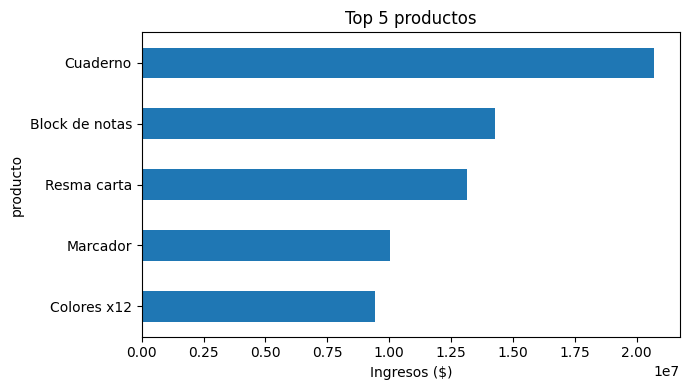

In [ ]:
# agrupamos las ventas por producto, sumamos los ingresos (total), los ordenamos de mayor a menor y nos quedamos con los 5 primeros
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
# creamos un gráfico de barras horizontales ordenado de menor a mayor, con un tamaño de 7 de ancho y 4 de alto, y un título
top_productos.sort_values().plot.barh(figsize=(7, 4), title="Top 5 productos")
# indica el eje x
plt.xlabel("Ingresos ($)")
# ayuda con los márgenes y la organización de la gráfica
plt.tight_layout()
plt.show()


In [ ]:
# ✅ Verificación
assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")

Ejercicio 1 correcto ✔


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

In [ ]:
# Ejercicio 2

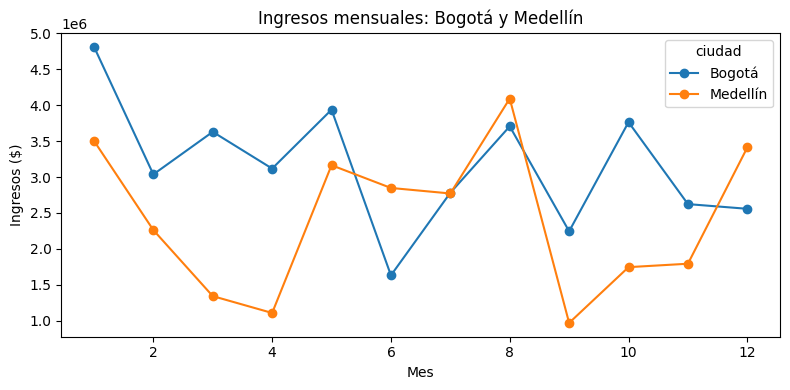

In [ ]:
# filtramos el documento para que solo queden las ventas de Bogotá y Medellín
dos_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]
# creamos una tabla dinámica con los meses en las filas, las ciudades en las columnas y la suma de las ventas (total) en cada casilla
ing_mes_ciudad = dos_ciudades.pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
# creamos un gráfico de líneas con un punto en cada mes, con un tamaño de 8 de ancho y 4 de alto, y un título
ing_mes_ciudad.plot.line(marker="o", figsize=(8, 4), title="Ingresos mensuales: Bogotá y Medellín")
# indica el eje x & y
plt.xlabel("Mes")
plt.ylabel("Ingresos ($)")
# ayuda con los márgenes y la organización de la gráfica
plt.tight_layout()
plt.show()


In [ ]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

Ejercicio 2 correcto ✔


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

In [ ]:
# Ejercicio 3

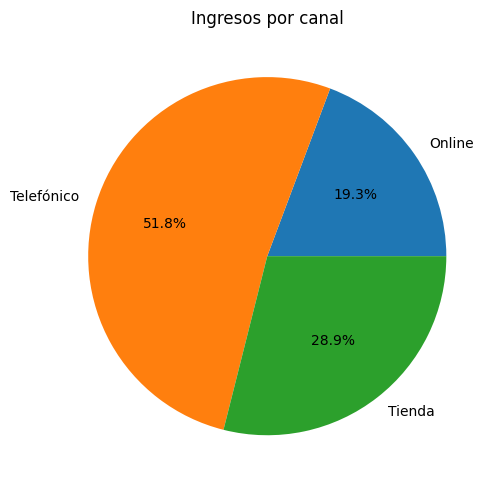

In [ ]:
# agrupamos las ventas por canal y sumamos los ingresos (total) de cada uno
ing_canal = df.groupby("canal")["total"].sum()
# creamos un gráfico de pie que muestra el porcentaje de cada canal con un decimal, con un tamaño de 6 de ancho y 5 de alto, y un título
ing_canal.plot.pie(autopct="%.1f%%", ylabel="", figsize=(6, 5), title="Ingresos por canal")
# ayuda con los márgenes y la organización de la gráfica
plt.tight_layout()
plt.show()


In [ ]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

Ejercicio 3 correcto ✔


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

In [ ]:
# Ejercicio 4

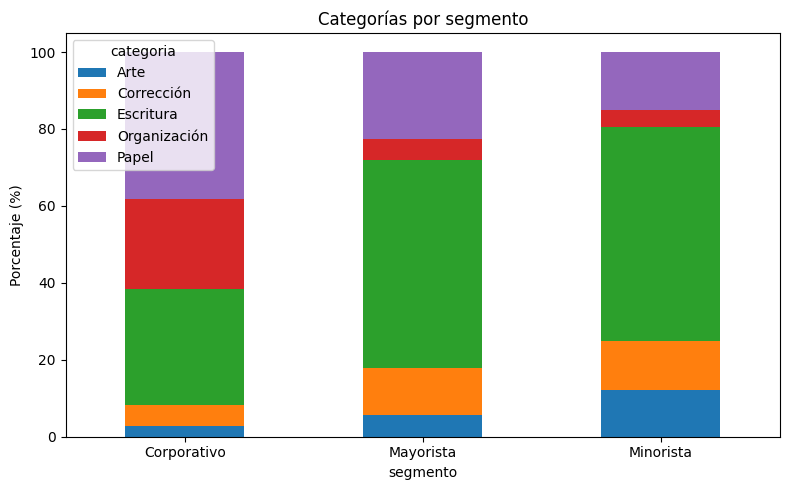

In [ ]:
# definimos la variable tabla_seg_cat la cual consiste en las columnas de segmento y categorias, y normaliza los numero es decir que solo pueden salir numero enteros, luego todo que se multipique por 100, para reprecentarlas las cifras en porcentajes
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
# creamos un grafico de barras que se organize la información de menor a mayor por las barras, con un tamaño de 8 de ancho y 5 de largo, y un titulo que diga categorias por segmento
tabla_seg_cat.plot.bar(stacked=True, figsize=(8, 5), title="Categorías por segmento")
# Incica la el label de y & x
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
# ayuda con las margenes y la organizacion de la grafica
plt.tight_layout()
plt.show()



In [ ]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

Ejercicio 4 correcto ✔


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

In [ ]:
# Ejercicio 5

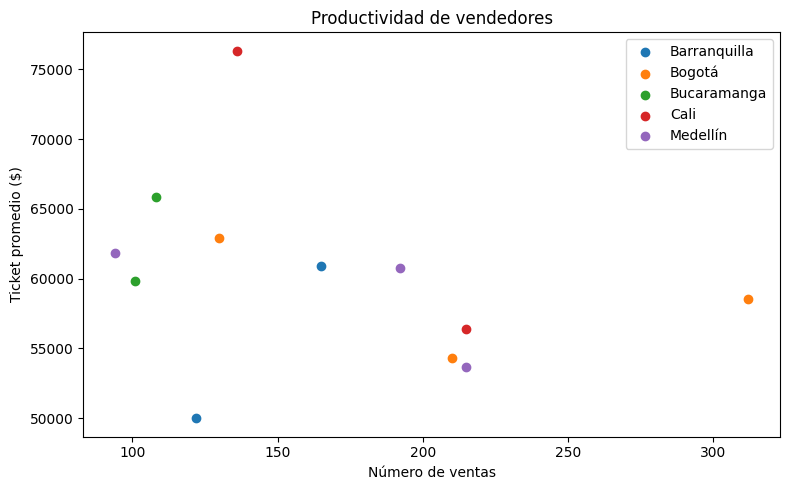

In [ ]:
# Agrupamos la informacion de la columna vender con la de ciudad
vend = df.groupby(["vendedor", "ciudad"]).agg(
    # creamos otra funcion le pedimos que cuente el id_ventas
    n_ventas=("id_venta", "count"),
    # luego con la informacion de la clumna total le queremos sacar el promedio y concertirla en el index
    ticket_prom=("total", "mean")).reset_index()
# definimos las dimenciones de la grafica
plt.figure(figsize=(8, 5))
# creamos la grafica utilizando los datos de cuidad, n_ventas y ticket_prom, funciones previamente creadas
for ciudad, datos in vend.groupby("ciudad"):
    plt.scatter(datos["n_ventas"], datos["ticket_prom"], label=ciudad)
plt.title("Productividad de vendedores")
plt.xlabel("Número de ventas")
plt.ylabel("Ticket promedio ($)")
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

Ejercicio 5 correcto ✔


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

In [ ]:
# Ejercicio 6

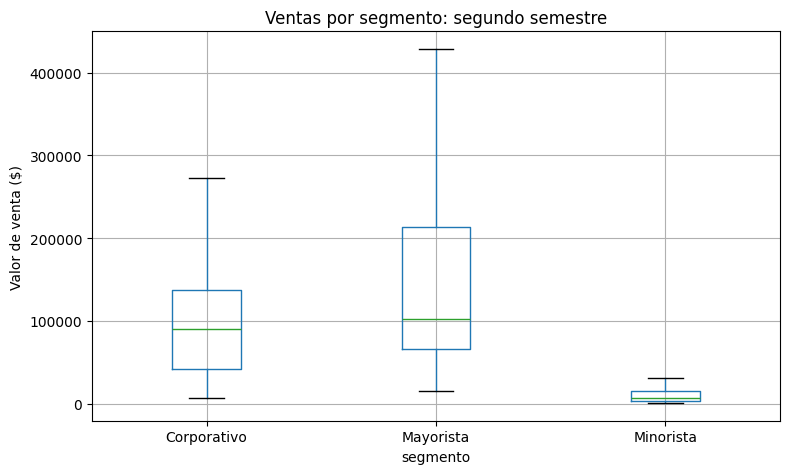

In [ ]:
sem2 = df[df["mes"] >= 7]
sem2.boxplot(column="total", by="segmento", showfliers=False, figsize=(8, 5))
plt.title("Ventas por segmento: segundo semestre")
plt.suptitle("")
plt.ylabel("Valor de venta ($)")
plt.tight_layout()
plt.show()



In [ ]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

Ejercicio 6 correcto ✔


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [ ]:
%%writefile figura_base.py
# Ejercicio 7: código de la figura 2x3
# Empieza con:  fig, axs = plt.subplots(2, 3, figsize=(18, 10))

Overwriting figura_base.py


In [ ]:
%%writefile figura_base.py
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(ax=axs[0, 0])
axs[0, 0].set_title("Top 5 productos")
axs[0, 0].set_xlabel("Ingresos ($)")

ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o")
axs[0, 1].set_title("Bogotá y Medellín por mes")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")

ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", ylabel="")
axs[0, 2].set_title("Ingresos por canal")

tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True)
axs[1, 0].set_title("Categorías por segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].tick_params(axis="x", rotation=0)

for ciudad, datos in vend.groupby("ciudad"):
    axs[1, 1].scatter(datos["n_ventas"], datos["ticket_prom"], label=ciudad)
axs[1, 1].set_title("Productividad de vendedores")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].legend(fontsize=8)

sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False)
axs[1, 2].set_title("Ventas por segmento, semestre 2")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor ($)")

fig.suptitle("Ventas de papelerías 2025", fontsize=16)
plt.tight_layout()


Overwriting figura_base.py


In [ ]:
%run -i figura_base.py

In [ ]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [ ]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===
fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(ax=axs[0, 0])
axs[0, 0].set_title("Top 5 productos")
axs[0, 0].set_xlabel("Ingresos ($)")

ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o")
axs[0, 1].set_title("Bogotá y Medellín por mes")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")

ing_canal.plot.pie(ax=axs[0, 2], autopct="%.1f%%", ylabel="")
axs[0, 2].set_title("Ingresos por canal")

tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True)
axs[1, 0].set_title("Categorías por segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].tick_params(axis="x", rotation=0)

for ciudad, datos in vend.groupby("ciudad"):
    axs[1, 1].scatter(datos["n_ventas"], datos["ticket_prom"], label=ciudad)
axs[1, 1].set_title("Productividad de vendedores")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].legend(fontsize=8)

sem2.boxplot(column="total", by="

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [ ]:
# con este prompt queremos que las graficas sean mas lindas visualmente, por lo que le especificamos utilizar una paleta de colores pastel con dondo blanco y disitntas carecteristicas que ayudan con la limpieza visual
prompt_v1 = """PÚBLICO Y OBJETIVO: Es para la gerente y el equipo comercial de la papelería. Quiero que entiendan rápido qué se vende más y cómo van las ventas.

PALETA Y TIPOGRAFÍA: Usa colores pastel que combinen: lila, azul claro, verde suave, durazno y rosado. Fondo claro, letras oscuras y títulos fáciles de leer. Que cada ciudad conserve su color.

TÍTULOS: Quiero estos nombres: "Cuaderno lidera", "Bogotá vs. Medellín", "Telefónico: 51,8 %", "Mezcla por segmento", "Volumen y ticket" y "Ventas en semestre 2".

EJES Y NÚMEROS: Muestra los ingresos en pesos o millones y los porcentajes con un decimal. Que los ejes tengan nombres claros.

LIMPIEZA VISUAL: Quita bordes innecesarios, deja una cuadrícula suave y muestra los valores sobre las barras. Deja espacio entre gráficos y no cambies los datos."""

print(prompt_v1)

PÚBLICO Y OBJETIVO: Es para la gerente y el equipo comercial de la papelería. Quiero que entiendan rápido qué se vende más y cómo van las ventas.

PALETA Y TIPOGRAFÍA: Usa colores pastel que combinen: lila, azul claro, verde suave, durazno y rosado. Fondo claro, letras oscuras y títulos fáciles de leer. Que cada ciudad conserve su color.

TÍTULOS: Quiero estos nombres: "Cuaderno lidera", "Bogotá vs. Medellín", "Telefónico: 51,8 %", "Mezcla por segmento", "Volumen y ticket" y "Ventas en semestre 2".

EJES Y NÚMEROS: Muestra los ingresos en pesos o millones y los porcentajes con un decimal. Que los ejes tengan nombres claros.

LIMPIEZA VISUAL: Quita bordes innecesarios, deja una cuadrícula suave y muestra los valores sobre las barras. Deja espacio entre gráficos y no cambies los datos.


In [ ]:
%%writefile figura_v1.py
# Pega aquí SOLO el código que te devolvió la IA (sin las líneas ```)

Overwriting figura_v1.py


In [ ]:
# corrimos el codigo y nos permitio visualisar las graficas nuevamente pero con los cambio que pedimos
%%writefile figura_v1.py
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

fondo = "#FBFAFD"
tinta = "#343448"
colores = ["#B9A7E8", "#9BC8E8", "#A9D6C1", "#F4BFA8", "#E9B5C4", "#F2DBA5"]
ciudades = {"Bogotá": "#B9A7E8", "Medellín": "#9BC8E8", "Cali": "#A9D6C1", "Barranquilla": "#F4BFA8", "Bucaramanga": "#E9B5C4"}
formato_m = FuncFormatter(lambda v, p: f"${v / 1e6:.0f} M")
formato_k = FuncFormatter(lambda v, p: f"${v / 1000:,.0f} mil")

fig, axs = plt.subplots(2, 3, figsize=(18, 10), facecolor=fondo)
for ax in axs.flat:
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#E7E4EE")
    ax.spines["bottom"].set_color("#E7E4EE")
    ax.tick_params(colors=tinta, labelsize=9)
    ax.title.set_color(tinta)

p = top_productos.sort_values()
p.plot.barh(ax=axs[0, 0], color=colores[:5], width=0.68)
axs[0, 0].set_title("Cuaderno lidera", fontsize=12, fontweight="bold")
axs[0, 0].set_xlabel("Ingresos")
axs[0, 0].xaxis.set_major_formatter(formato_m)
axs[0, 0].grid(axis="x", color="#EEEAF3", alpha=0.8)
axs[0, 0].set_axisbelow(True)
for i, v in enumerate(p):
    axs[0, 0].text(v + p.max() * 0.015, i, f"${v / 1e6:.1f} M", va="center", fontsize=9, color=tinta)
axs[0, 0].set_xlim(0, p.max() * 1.24)

for ciudad in ["Bogotá", "Medellín"]:
    axs[0, 1].plot(ing_mes_ciudad.index, ing_mes_ciudad[ciudad], marker="o", markersize=4, linewidth=2.3, label=ciudad, color=ciudades[ciudad])
axs[0, 1].set_title("Bogotá vs. Medellín", fontsize=12, fontweight="bold")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos")
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].yaxis.set_major_formatter(formato_m)
axs[0, 1].grid(axis="y", color="#EEEAF3")
axs[0, 1].legend(frameon=False, fontsize=9)

ing_canal.plot.pie(ax=axs[0, 2], colors=colores[:3], autopct="%.1f%%", startangle=90, ylabel="", textprops={"color":tinta, "fontsize":10}, wedgeprops={"edgecolor":"white", "linewidth":2})
axs[0, 2].set_title("Telefónico: 51,8 %", fontsize=12, fontweight="bold")

categorias = list(tabla_seg_cat.columns)
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, color=colores[:len(categorias)], width=0.65)
axs[1, 0].set_title("Mezcla por segmento", fontsize=12, fontweight="bold")
axs[1, 0].set_xlabel("")
axs[1, 0].set_ylabel("Participación (%)")
axs[1, 0].tick_params(axis="x", rotation=0)
axs[1, 0].legend(title="Categoría", fontsize=8, title_fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))

for ciudad, datos in vend.groupby("ciudad"):
    axs[1, 1].scatter(datos["n_ventas"], datos["ticket_prom"], label=ciudad, s=90, alpha=0.85, color=ciudades[ciudad], edgecolor="white", linewidth=1)
axs[1, 1].set_title("Volumen y ticket", fontsize=12, fontweight="bold")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio")
axs[1, 1].yaxis.set_major_formatter(formato_k)
axs[1, 1].grid(color="#EEEAF3")
axs[1, 1].set_axisbelow(True)
axs[1, 1].legend(frameon=False, fontsize=7, ncol=2)

sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], showfliers=False, patch_artist=True, boxprops={"facecolor":colores[0], "edgecolor":tinta}, medianprops={"color":"#B16F87", "linewidth":2}, whiskerprops={"color":tinta}, capprops={"color":tinta})
axs[1, 2].set_title("Ventas en semestre 2", fontsize=12, fontweight="bold")
axs[1, 2].set_xlabel("")
axs[1, 2].set_ylabel("Valor por venta")
axs[1, 2].yaxis.set_major_formatter(formato_k)

fig.suptitle("Ventas de papelerías | 2025", fontsize=19, color=tinta, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.96], w_pad=3.8, h_pad=3)



Overwriting figura_v1.py


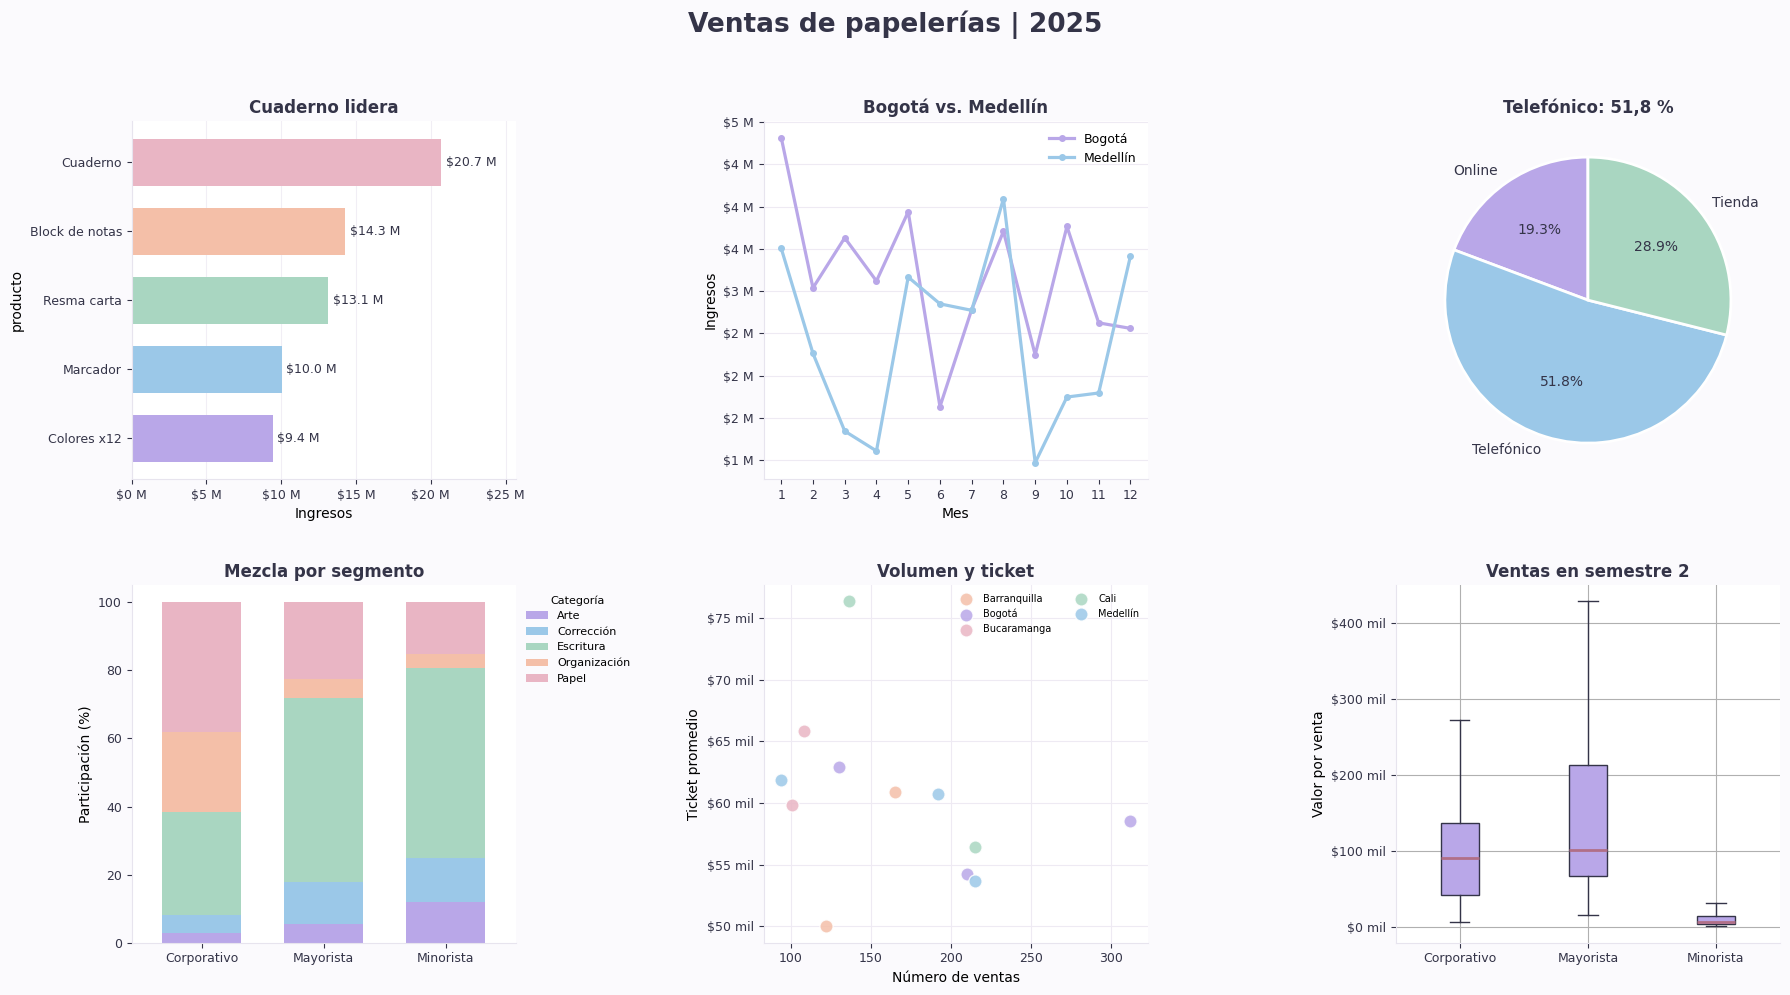

In [ ]:
mostrar ("v1")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [ ]:
prompt_v2 = prompt_v1 + """

AJUSTES: Me gustó, pero quiero cambiar algunas cosas:
1. La leyenda de categorías está pegada al otro gráfico. Ponla debajo en columnas.
2. Cambia el gráfico de pie por una dona y destaca en el centro el 51,8 % del canal telefónico.
3. Marca en el gráfico de vendedores quién hizo más ventas y quién tiene el ticket promedio más alto.
4. Haz las letras más fáciles de leer y conserva los mismos colores pastel."""

print(prompt_v2)

PÚBLICO Y OBJETIVO: Es para la gerente y el equipo comercial de la papelería. Quiero que entiendan rápido qué se vende más y cómo van las ventas.

PALETA Y TIPOGRAFÍA: Usa colores pastel que combinen: lila, azul claro, verde suave, durazno y rosado. Fondo claro, letras oscuras y títulos fáciles de leer. Que cada ciudad conserve su color.

TÍTULOS: Quiero estos nombres: "Cuaderno lidera", "Bogotá vs. Medellín", "Telefónico: 51,8 %", "Mezcla por segmento", "Volumen y ticket" y "Ventas en semestre 2".

EJES Y NÚMEROS: Muestra los ingresos en pesos o millones y los porcentajes con un decimal. Que los ejes tengan nombres claros.

LIMPIEZA VISUAL: Quita bordes innecesarios, deja una cuadrícula suave y muestra los valores sobre las barras. Deja espacio entre gráficos y no cambies los datos.

AJUSTES: Me gustó, pero quiero cambiar algunas cosas:
1. La leyenda de categorías está pegada al otro gráfico. Ponla debajo en columnas.
2. Cambia el gráfico de pie por una dona y destaca en el centro el 

In [ ]:
%%writefile figura_v2.py
# Pega aquí el código que te devolvió la IA para la versión 2

In [ ]:
%%writefile figura_v2.py
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

FONDO = "#FAF9FD"
TEXTO = "#353347"
SUAVE = "#EAE7EF"
PASTEL = ["#BBAAE5", "#A6CBE8", "#ABD7C4", "#F4C0A7", "#E8B5C9", "#F0D9A3"]
CIUDAD = {"Bogotá":"#BBAAE5", "Medellín":"#A6CBE8", "Cali":"#ABD7C4", "Barranquilla":"#F4C0A7", "Bucaramanga":"#E8B5C9"}
fmt_m = FuncFormatter(lambda x, pos: f"${x / 1e6:.0f} M")
fmt_k = FuncFormatter(lambda x, pos: f"${x / 1000:,.0f} mil")

fig, axs = plt.subplots(2, 3, figsize=(18, 10), facecolor=FONDO)
fig.subplots_adjust(left=0.065, right=0.965, top=0.82, bottom=0.10, wspace=0.46, hspace=0.64)

for ax in axs.flat:
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(SUAVE)
    ax.spines["bottom"].set_color(SUAVE)
    ax.tick_params(colors=TEXTO, labelsize=9, length=0, pad=6)
    ax.set_axisbelow(True)

# 1. Productos
p = top_productos.sort_values()
axs[0, 0].barh(p.index, p.values, color=PASTEL[:5], height=0.64)
axs[0, 0].set_title("Cuaderno lidera los ingresos", loc="left", fontsize=12, color=TEXTO, fontweight="semibold", pad=14)
axs[0, 0].xaxis.set_major_formatter(fmt_m)
axs[0, 0].grid(axis="x", color=SUAVE, linewidth=0.7)
axs[0, 0].set_xlim(0, p.max() * 1.3)
for i, valor in enumerate(p.values):
    axs[0, 0].text(valor + p.max() * 0.025, i, f"${valor / 1e6:.1f} M", va="center", fontsize=9, color=TEXTO)
axs[0, 0].set_xlabel("Ingresos ($ millones)", color=TEXTO, fontsize=9)

# 2. Ciudades
for ciudad in ["Bogotá", "Medellín"]:
    axs[0, 1].plot(ing_mes_ciudad.index, ing_mes_ciudad[ciudad], label=ciudad, color=CIUDAD[ciudad], linewidth=2.4, marker="o", markersize=4.5)
axs[0, 1].set_title("Bogotá supera a Medellín", loc="left", fontsize=12, color=TEXTO, fontweight="semibold", pad=14)
axs[0, 1].set_xticks(range(1, 13))
axs[0, 1].set_xlabel("Mes", color=TEXTO, fontsize=9)
axs[0, 1].set_ylabel("Ingresos", color=TEXTO, fontsize=9)
axs[0, 1].yaxis.set_major_formatter(fmt_m)
axs[0, 1].grid(axis="y", color=SUAVE, linewidth=0.7)
axs[0, 1].legend(frameon=False, fontsize=9, loc="upper right")

# 3. Dona por canal
axs[0, 2].pie(ing_canal.values, labels=ing_canal.index, colors=PASTEL[:len(ing_canal)], autopct="%.1f%%", pctdistance=0.83, labeldistance=1.08, startangle=90, wedgeprops={"width":0.32, "edgecolor":"white", "linewidth":3}, textprops={"fontsize":9, "color":TEXTO})
axs[0, 2].set_title("Telefónico concentra 51,8 %", loc="left", fontsize=12, color=TEXTO, fontweight="semibold", pad=14)
axs[0, 2].text(0, 0.06, "51,8 %", ha="center", va="center", fontsize=19, color=TEXTO, fontweight="bold")
axs[0, 2].text(0, -0.19, "telefónico", ha="center", va="center", fontsize=10, color=TEXTO)

# 4. Segmentos
cats = list(tabla_seg_cat.columns)
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, width=0.64, color=PASTEL[:len(cats)], legend=False)
axs[1, 0].set_title("Las categorías cambian por segmento", loc="left", fontsize=11.5, color=TEXTO, fontweight="semibold", pad=14)
axs[1, 0].tick_params(axis="x", rotation=0)
axs[1, 0].set_xlabel("")
axs[1, 0].set_ylabel("% de ventas", color=TEXTO, fontsize=9)
axs[1, 0].set_ylim(0, 105)
axs[1, 0].grid(axis="y", color=SUAVE, linewidth=0.7)
axs[1, 0].legend(cats, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=7.5, frameon=False)

# 5. Vendedores
for ciudad, datos in vend.groupby("ciudad"):
    axs[1, 1].scatter(datos["n_ventas"], datos["ticket_prom"], s=105, label=ciudad, color=CIUDAD[ciudad], edgecolors="white", linewidth=1.2, alpha=0.97)
axs[1, 1].set_title("Más ventas no siempre es mayor ticket", loc="left", fontsize=11.5, color=TEXTO, fontweight="semibold", pad=14)
axs[1, 1].set_xlabel("Número de ventas", color=TEXTO, fontsize=9)
axs[1, 1].set_ylabel("Ticket promedio", color=TEXTO, fontsize=9)
axs[1, 1].yaxis.set_major_formatter(fmt_k)
axs[1, 1].grid(color=SUAVE, linewidth=0.7)
mayor_ventas = vend.loc[vend["n_ventas"].idxmax()]
mayor_ticket = vend.loc[vend["ticket_prom"].idxmax()]
axs[1, 1].annotate("Más ventas", xy=(mayor_ventas["n_ventas"], mayor_ventas["ticket_prom"]), xytext=(-62, 20), textcoords="offset points", arrowprops={"arrowstyle":"-", "color":TEXTO, "lw":0.8}, fontsize=8, color=TEXTO)
axs[1, 1].annotate("Mayor ticket", xy=(mayor_ticket["n_ventas"], mayor_ticket["ticket_prom"]), xytext=(12, -12), textcoords="offset points", arrowprops={"arrowstyle":"-", "color":TEXTO, "lw":0.8}, fontsize=8, color=TEXTO)
axs[1, 1].legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.24), fontsize=7.5, frameon=False)

# 6. Cajas
segmentos = sorted(sem2["segmento"].unique())
axs[1, 2].boxplot([sem2.loc[sem2["segmento"] == seg, "total"] for seg in segmentos], tick_labels=segmentos, showfliers=False, patch_artist=True, boxprops={"facecolor":PASTEL[2], "edgecolor":"#787184", "linewidth":1}, medianprops={"color":"#AF6F91", "linewidth":2.4}, whiskerprops={"color":"#787184"}, capprops={"color":"#787184"})
axs[1, 2].set_title("Mayorista tiene tickets más altos", loc="left", fontsize=12, color=TEXTO, fontweight="semibold", pad=14)
axs[1, 2].set_xlabel("")
axs[1, 2].set_ylabel("Valor por venta", color=TEXTO, fontsize=9)
axs[1, 2].yaxis.set_major_formatter(fmt_k)
axs[1, 2].grid(axis="y", color=SUAVE, linewidth=0.7)

fig.suptitle("PAPELERÍAS 2025  /  PANORAMA COMERCIAL", x=0.065, ha="left", fontsize=21, color=TEXTO, fontweight="bold", y=0.985)
fig.text(0.065, 0.927, "2.000 ventas  ·  5 ciudades  ·  Comparativo de productos, canales y segmentos", color="#777184", fontsize=11)


Overwriting figura_v2.py


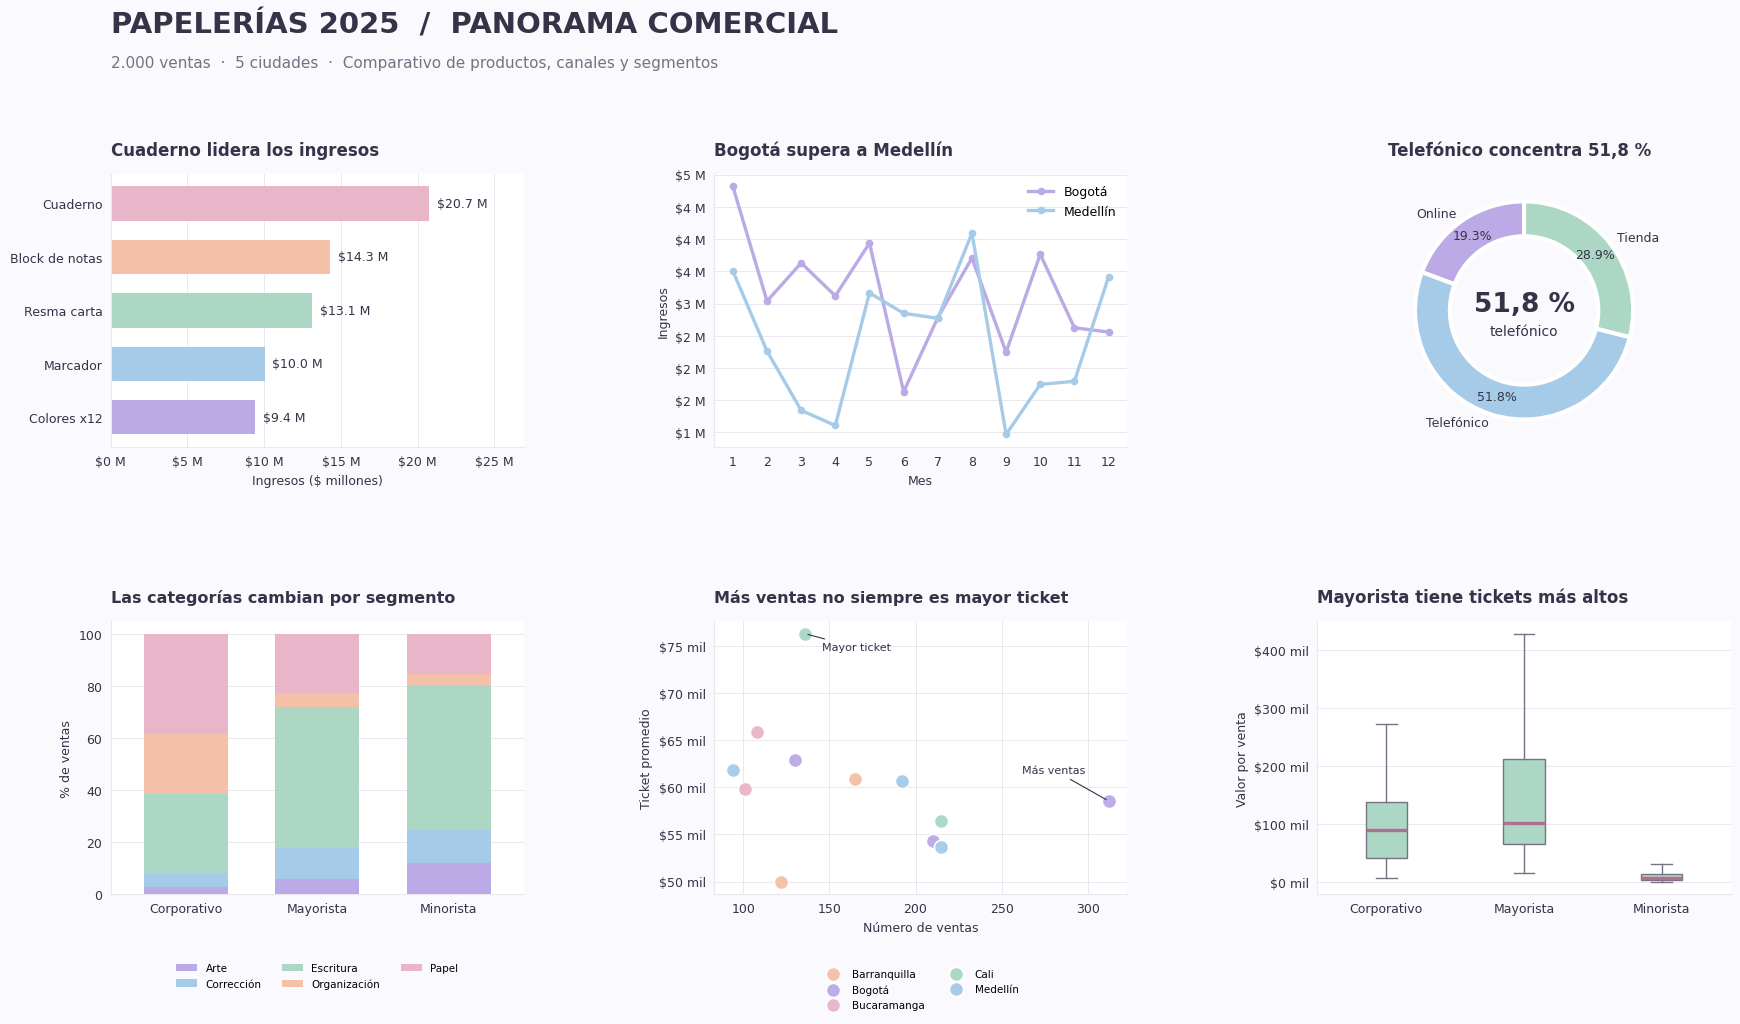

In [ ]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [ ]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# print(prompt_v3)

In [ ]:
# ✅ Verificación
import os
assert os.path.exists("figura_v1.py") and os.path.exists("figura_v2.py"), "Faltan figura_v1.py y figura_v2.py: pega el código de cada versión"
assert "ESCRIBE AQUÍ" not in prompt_v1 and prompt_v2 != prompt_v1 and "ESCRIBE AQUÍ" not in prompt_v2, "Completa tus prompts v1 y v2"
print("Parte C correcta ✔")

---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [ ]:
figura_elegida = "v2"

hallazgos = [
    "Cuaderno fue el producto con mayores ingresos: $20.712.345 en 2025.",
    "El canal telefónico generó $61.450.716, equivalente al 51,8 % de los ingresos.",
    "Bogotá vendió $37.847.614, por encima de los $29.015.462 de Medellín."
]


In [ ]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

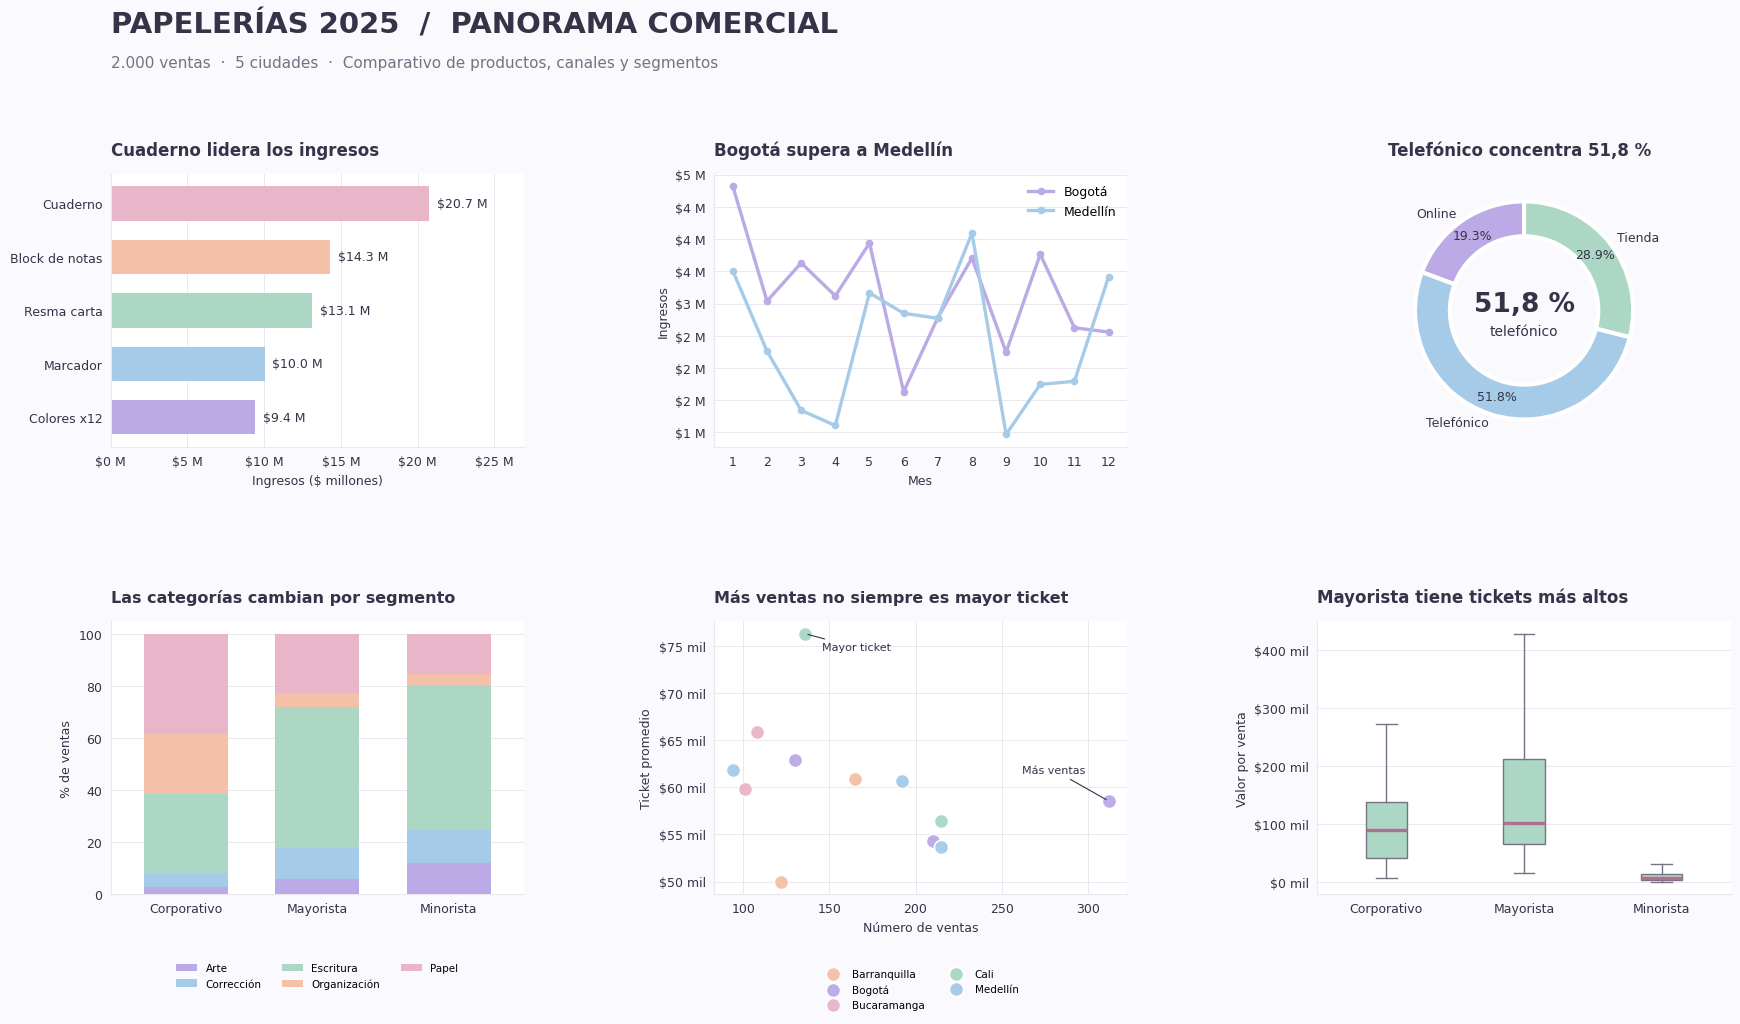

Hallazgos:
• Cuaderno fue el producto con mayores ingresos: $20.712.345 en 2025.
• El canal telefónico generó $61.450.716, equivalente al 51,8 % de los ingresos.
• Bogotá vendió $37.847.614, por encima de los $29.015.462 de Medellín.


In [ ]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.